# 03 · Module 2: prediction-preserving, branch-specific stability

**Research question 2.** How stable is each branch's explanation under small changes of the raw ECG that do not change its prediction?

**Perturbation set** (30 per recording, applied to the raw signal; both inputs are regenerated, the image by re-rendering):
amplitude scaling ×{0.8, 0.9, 0.95, 1.05, 1.1, 1.2}; baseline drift at 0.3 Hz, amplitude 0.05 or 0.10, six phases; Gaussian noise σ = 0.05 or 0.10, six seeds.

**Acceptance.** A perturbation contributes to branch $b$ only if branch $b$ keeps its prediction. Prediction retention (PRR) is reported separately.

**Stability.** Over accepted perturbations, $\mu_b(u)$ is the mean attribution and $S_b(u)=1-\sigma_b(u)/(\max_u\sigma_b+\varepsilon)$ the local stability;
$H_b=\mu_b S_b$ is the stability-weighted map used by Module 3.
The maps were produced on the HPC by `src/hpc_pipeline/03_module2_stability/run_dan_module2_noise_stability.py`; this notebook analyses the archived output.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd().resolve().parent          # repository root (notebooks/ is one level down)
sys.path.insert(0, str(ROOT / 'src'))
ARCH = ROOT / 'data' / 'archived'           # archived HPC outputs (inputs of this notebook)
TAB = ROOT / 'results' / 'tables'           # tables written by the notebooks
FIG = ROOT / 'results' / 'figures'          # figures written by the notebooks (used in the report)
TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40); pd.set_option('display.precision', 4)
warnings.filterwarnings('ignore', category=RuntimeWarning)
CLASSES = ['AFib', 'GSVT', 'SB', 'SR']
def show(name, width=900):
    """Display a figure that a plotting function saved to results/figures."""
    display(Image(filename=str(FIG / f'{name}.png'), width=width))
print('repository root:', ROOT.name)

repository root: DAN-MMGradCAM


In [2]:
from scipy.stats import wilcoxon
rng = np.random.default_rng(20261117)
z = np.load(ARCH / 'module2/noise_stability_maps.npz')
rec = pd.read_csv(ARCH / 'module2/noise_stability_records.csv')
V = z['valid_600'].astype(bool)
rec['both_correct'] = (rec.pred_1d == rec.class_name) & (rec.pred_2d == rec.class_name)
print('perturbations:', list(z['pert_names']))
print('records:', len(rec), '| both correct:', int(rec.both_correct.sum()))

perturbations: [np.str_('scale_0.8'), np.str_('scale_0.9'), np.str_('scale_0.95'), np.str_('scale_1.05'), np.str_('scale_1.1'), np.str_('scale_1.2'), np.str_('drift_0.05_0.000'), np.str_('drift_0.05_1.047'), np.str_('drift_0.05_2.094'), np.str_('drift_0.05_3.142'), np.str_('drift_0.05_4.189'), np.str_('drift_0.05_5.236'), np.str_('drift_0.1_0.000'), np.str_('drift_0.1_1.047'), np.str_('drift_0.1_2.094'), np.str_('drift_0.1_3.142'), np.str_('drift_0.1_4.189'), np.str_('drift_0.1_5.236'), np.str_('noise_0.05_0'), np.str_('noise_0.05_1'), np.str_('noise_0.05_2'), np.str_('noise_0.05_3'), np.str_('noise_0.05_4'), np.str_('noise_0.05_5'), np.str_('noise_0.1_0'), np.str_('noise_0.1_1'), np.str_('noise_0.1_2'), np.str_('noise_0.1_3'), np.str_('noise_0.1_4'), np.str_('noise_0.1_5')]
records: 1054 | both correct: 939


## 1. Prediction retention

In [3]:
fam = ['scale', 'drift_0.05', 'drift_0.1', 'noise_0.05', 'noise_0.1']
prr = pd.DataFrame({f: {'1D': rec[f'prr_1d_{f}'].mean(), '2D': rec[f'prr_2d_{f}'].mean()} for f in fam}).T
prr['all 30'] = [np.nan] * len(prr)
prr.loc['all 30'] = [rec.prr_1d.mean(), rec.prr_2d.mean(), np.nan]
prr = prr.drop(columns='all 30')
prr.to_csv(TAB / 'module2_prr_by_perturbation.csv')
display((100 * prr).round(2).rename(columns=lambda c: c + ' PRR %'))
acc = rec[rec.both_correct].n_joint_accepted
print(f'jointly accepted perturbations (primary cohort): median {acc.median():.0f}, '
      f'all 30 accepted in {int((acc == 30).sum())} of {len(acc)} recordings')

,1D PRR %,2D PRR %
scale,98.88,98.36
drift_0.05,96.82,98.36
drift_0.1,94.86,95.98
noise_0.05,99.00,98.85
noise_0.1,97.34,96.38
all 30,97.38,97.58


jointly accepted perturbations (primary cohort): median 30, all 30 accepted in 752 of 939 recordings


## 2. Explanation stability

In [4]:
EPS = 1e-12
def topk(x, f=.15):
    k = int(np.ceil(f * x.size)); s = np.zeros(x.size, bool); s[np.argsort(-x, kind='stable')[:k]] = True; return s
rows = []
for i in np.flatnonzero(rec.both_correct):
    v = V[i]; mu1, mu2, S1, S2 = (z[k][i][v] for k in ('mu1', 'mu2', 'S1', 'S2'))
    s1, s2 = topk(mu1), topk(mu2)
    rows.append({'cohort_index': rec.cohort_index[i], 'class_name': rec.class_name[i],
                 'S1_mean': S1.mean(), 'S2_mean': S2.mean(),
                 'S1_salient': S1[s1].mean(), 'S1_rest': S1[~s1].mean(),
                 'S2_salient': S2[s2].mean(), 'S2_rest': S2[~s2].mean()})
st = pd.DataFrame(rows); st.to_csv(TAB / 'module2_stability_per_record.csv', index=False)
def ci(x):
    b = [np.median(rng.choice(x, x.size)) for _ in range(2000)]; return '%.3f–%.3f' % tuple(np.percentile(b, [2.5, 97.5]))
tab = st.groupby('class_name')[['S1_mean', 'S2_mean', 'S1_salient', 'S1_rest', 'S2_salient', 'S2_rest']].median()
tab.loc['All'] = st[tab.columns].median()
tab['S2 − S1 (median)'] = list(st.groupby('class_name').apply(lambda g: (g.S2_mean - g.S1_mean).median())) + [(st.S2_mean - st.S1_mean).median()]
tab.to_csv(TAB / 'module2_stability_by_class.csv')
print('95% CI of the median S2 − S1 (all):', ci((st.S2_mean - st.S1_mean).to_numpy()))
print('Wilcoxon S1 vs S2: p = %.2e' % wilcoxon(st.S1_mean, st.S2_mean).pvalue)
print('Wilcoxon 2D salient vs rest: p = %.2e' % wilcoxon(st.S2_salient, st.S2_rest).pvalue)
print('Wilcoxon 1D salient vs rest: p = %.2e' % wilcoxon(st.S1_salient, st.S1_rest).pvalue)
tab.round(3)

95% CI of the median S2 − S1 (all): -0.363–-0.353
Wilcoxon S1 vs S2: p = 0.00e+00
Wilcoxon 2D salient vs rest: p = 1.54e-42
Wilcoxon 1D salient vs rest: p = 0.00e+00


,S1_mean,S2_mean,S1_salient,S1_rest,S2_salient,S2_rest,S2 − S1 (median)
class_name,,,,,,,
AFib,0.815,0.473,0.515,0.874,0.415,0.480,-0.351
GSVT,0.798,0.462,0.510,0.853,0.418,0.472,-0.336
SB,0.846,0.461,0.458,0.914,0.405,0.466,-0.376
SR,0.802,0.449,0.488,0.856,0.446,0.447,-0.357
All,0.818,0.462,0.484,0.877,0.418,0.468,-0.358


**Reading.** Both CNNs keep their prediction under most perturbations, but the 2D explanation is much less stable than the 1D explanation,
and in the 2D branch the most attributed columns are less stable than the rest. Prediction stability therefore does not imply explanation stability.

saved fig_module2_detail


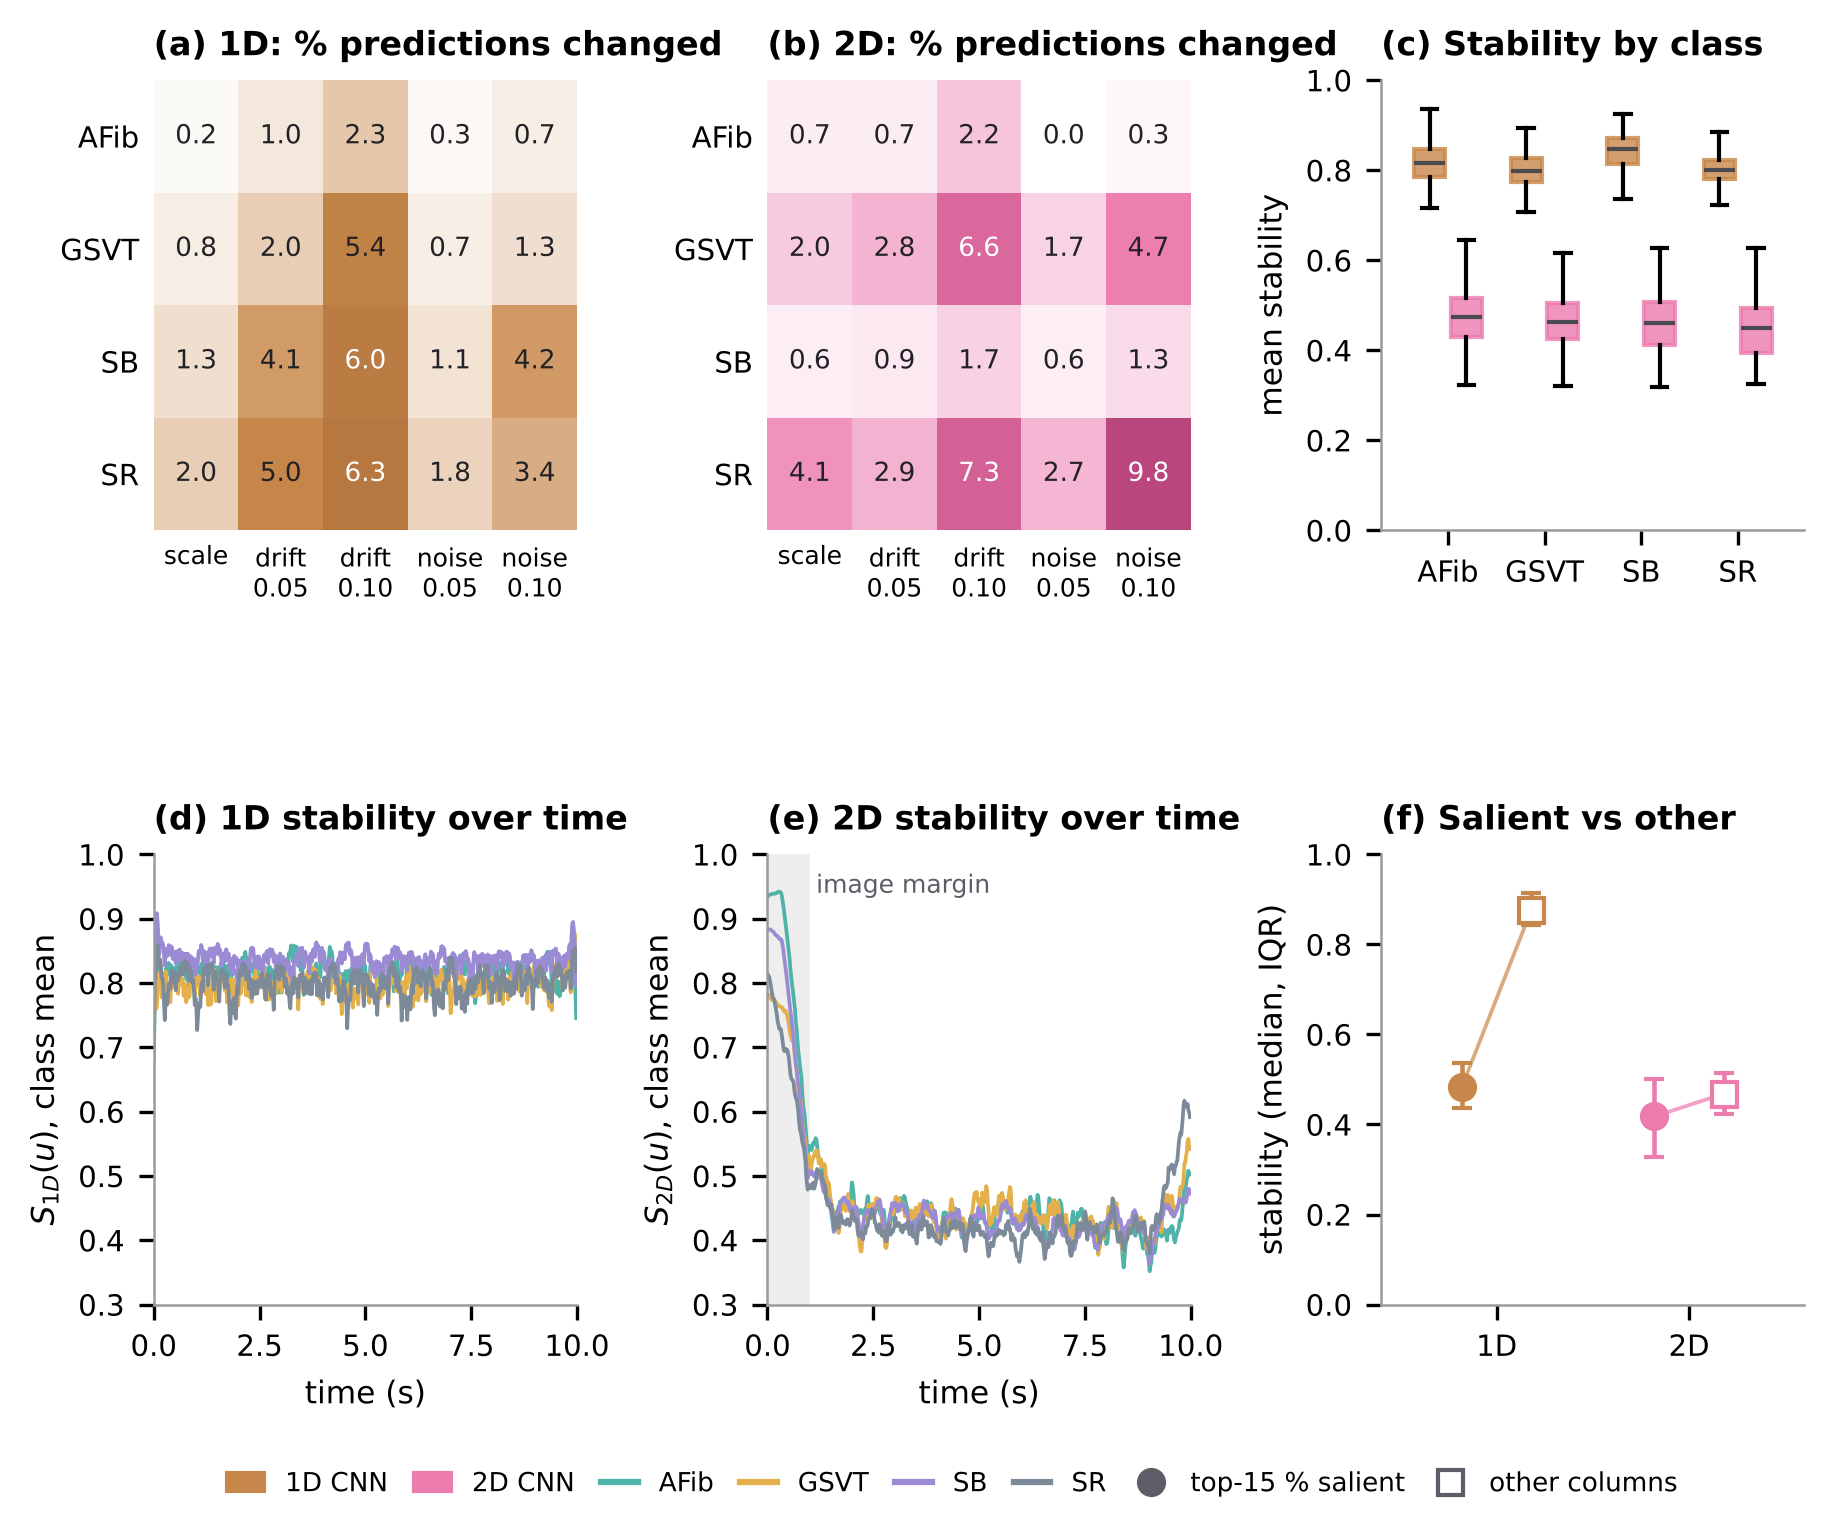

In [5]:
import dan_figures as F
per = pd.read_csv(TAB / 'module1_per_record.csv')
per = per.merge(st.drop(columns='class_name'), on='cohort_index', how='left')
per['both_correct'] = per.both_correct.fillna(False).astype(bool)
F.fig_module2_detail(z, rec, per, FIG)
show('fig_module2_detail', 800)